In [1]:
import ezdxf

file_path = "example.dxf"
doc = ezdxf.readfile(file_path)
msp = doc.modelspace()

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [31]:
for entity in msp.query("LINE"):
    x,y,z = entity.dxf.start
    print(x,y)

0.0 0.0
1000.0 0.0
500.0 -866.0254037844385
500.0 -866.0254037844385
500.0 -866.0254037844385
1000.0 0.0
1500.0 -866.0254037844385


In [35]:
for entity in msp:
    print(entity.dxftype(), entity.dxf.handle)

LINE 2C8
LINE 2C9
LINE 2CD
LINE 2CE
LINE 2CF
LINE 2D0
LINE 2D1


In [38]:
import ezdxf

doc = ezdxf.new("R2010")
msp = doc.modelspace()

# --------------------------------------------------
# Test 1: Simple cross
#
#        |
#        |
# -------+-------
#        |
#        |
#
# Expected: 4 members after splitting
# --------------------------------------------------

msp.add_line((-5000, 0), (5000, 0))
msp.add_line((0, -5000), (0, 5000))

# --------------------------------------------------
# Test 2: T-junction
#
#          |
#          |
# ---------+--------
#
# Expected:
# horizontal -> 2 members
# vertical   -> 1 member
# total      -> 3 members
# --------------------------------------------------

msp.add_line((10000, 0), (20000, 0))
msp.add_line((15000, 0), (15000, 3000))

# --------------------------------------------------
# Test 3: X-junction
#
# \       /
#  \     /
#   \   /
#    \ /
#    / \
#   /   \
#  /     \
# /       \
#
# Expected:
# each diagonal split into 2
# total 4 members
# --------------------------------------------------

msp.add_line((30000, 0), (40000, 10000))
msp.add_line((30000, 10000), (40000, 0))

# --------------------------------------------------
# Test 4: Already segmented
#
# ----+----
#
# Expected: still 2 members
# --------------------------------------------------

msp.add_line((50000, 0), (55000, 0))
msp.add_line((55000, 0), (60000, 0))

# --------------------------------------------------
# Test 5: Small coordinate mismatch
#
# Intended to test node merging tolerance
# --------------------------------------------------

msp.add_line((70000, 0), (75000, 0))
msp.add_line((75000.2, 0), (80000, 0))

# horizontal
msp.add_line((0, 20000), (10000, 20000))

# vertical
msp.add_line((5000, 15000), (5000, 25000))

# diagonal
msp.add_line((2000, 17000), (8000, 23000))


doc.saveas("splitting_test.dxf")

print("Written: splitting_test.dxf")


Written: splitting_test.dxf


In [ ]:
import ezdxf

doc = ezdxf.new("R2010")
msp = doc.modelspace()

# Square
msp.add_line((0, 0), (4000, 0))
msp.add_line((4000, 0), (4000, 4000))
msp.add_line((4000, 4000), (0, 4000))
msp.add_line((0, 4000), (0, 0))

# Ends
msp.add_line((-4000, 0), (0, 0))
msp.add_line((-4000, 0), (0, 4000))
msp.add_line((8000, 0), (4000, 0))
msp.add_line((8000, 0), (4000, 4000))

# First diagonal
msp.add_line((0, 0), (4000, 4000))

# Second diagonal
msp.add_line((4000, 0), (0, 4000))

DXF = "truss1.dxf"
doc.saveas(DXF)

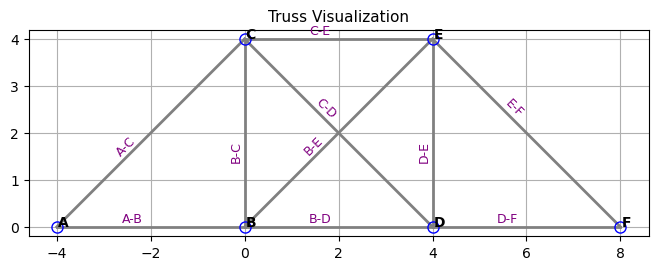

In [2]:
from import_functions import extract_structure_from_dxf
from visualisation import visualize_truss
DXF = "truss1.dxf"
nodes, members = extract_structure_from_dxf(DXF, units='mm', tol=0.1)
fig,ax = visualize_truss(nodes, members, textscale=1, show_node_labels=True, show_member_labels=True)

In [12]:
import ezdxf

# Create DXF
doc = ezdxf.new("R2010")
msp = doc.modelspace()

# ==================================================
# Geometry (mm)
# ==================================================

tower_height = 12000
tower_width = 4000

tank_height = 3000
tank_width = 6000

n_panels = 4

# ==================================================
# Tapered tower geometry
# ==================================================

base_width = 6000      # width at ground
top_width = 3000       # width at tank support

panel_h = tower_height / n_panels

# Store node locations on each level
levels = []

for i in range(n_panels + 1):

    y = i * panel_h

    # Linear taper
    width = base_width - (base_width - top_width) * y / tower_height

    left_x = -width / 2
    right_x = width / 2

    levels.append((left_x, right_x, y))

# ==================================================
# Legs
# ==================================================

for i in range(n_panels):

    lx1, rx1, y1 = levels[i]
    lx2, rx2, y2 = levels[i + 1]

    msp.add_line((lx1, y1), (lx2, y2))
    msp.add_line((rx1, y1), (rx2, y2))

# ==================================================
# Horizontal members and X bracing
# ==================================================

for i in range(n_panels):

    lx1, rx1, y1 = levels[i]
    lx2, rx2, y2 = levels[i + 1]

    # Upper panel beam
    msp.add_line((lx2, y2), (rx2, y2))

    # X brace
    msp.add_line((lx1, y1), (rx2, y2))
    msp.add_line((rx1, y1), (lx2, y2))


# ==================================================
# Save
# ==================================================

doc.saveas("water_tower_truss.dxf")

print("Created water_tower_truss.dxf")

Created water_tower_truss.dxf


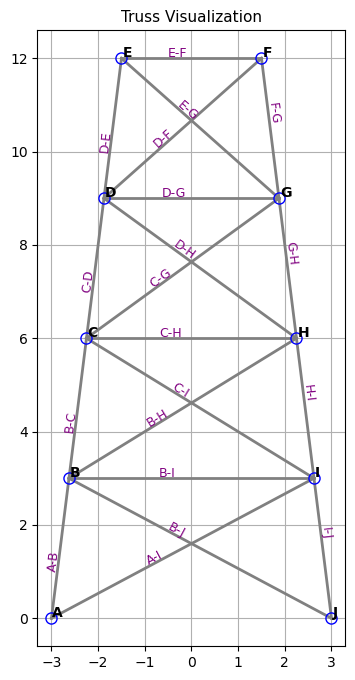

In [13]:
from import_functions import extract_structure_from_dxf
from visualisation import visualize_truss
DXF = "water_tower_truss.dxf"
nodes, members = extract_structure_from_dxf(DXF, units='mm', tol=0.1)
fig,ax = visualize_truss(nodes, members, textscale=1, show_node_labels=True, show_member_labels=True)